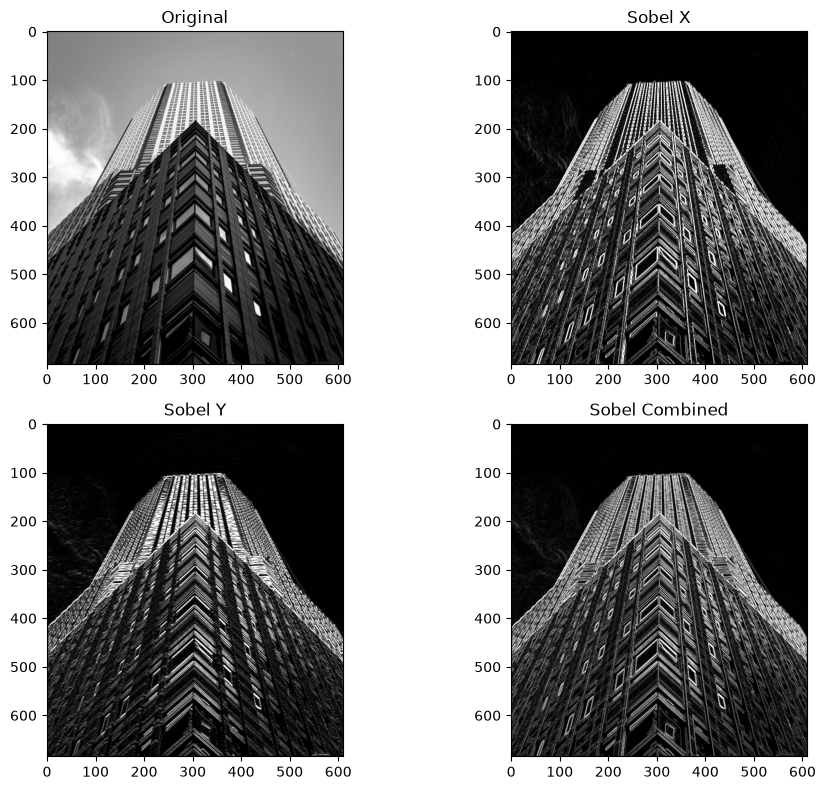

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image in grayscale
img = cv2.imread("building.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Upload building.png into the notebook folder")

# Sobel X direction
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)

# Sobel Y direction
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

# Convert to 8-bit
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

# Combine edges
sobel_combined = cv2.addWeighted(
    sobel_x_abs, 0.5,
    sobel_y_abs, 0.5, 0
)

# Display results
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")

plt.subplot(2, 2, 2)
plt.imshow(sobel_x_abs, cmap="gray")
plt.title("Sobel X")

plt.subplot(2, 2, 3)
plt.imshow(sobel_y_abs, cmap="gray")
plt.title("Sobel Y")

plt.subplot(2, 2, 4)
plt.imshow(sobel_combined, cmap="gray")
plt.title("Sobel Combined")

plt.tight_layout()
plt.show()

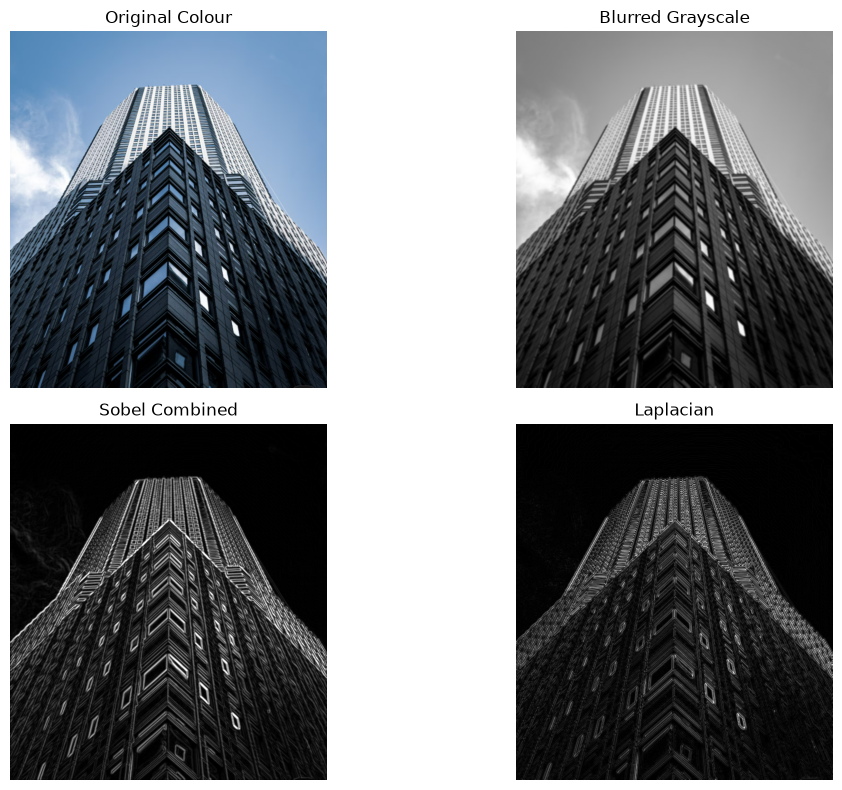

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load colour image
img_color = cv2.imread("building.png")

if img_color is None:
    raise FileNotFoundError("Upload building.png")

# Convert to RGB and grayscale
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Apply Gaussian blur
blurred = cv2.GaussianBlur(img_gray, (5, 5), 1)

# Sobel edge detection
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

sobel_combined = cv2.addWeighted(
    sobel_x_abs, 0.5,
    sobel_y_abs, 0.5, 0
)

# Laplacian edge detection
laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=3)
laplacian_abs = cv2.convertScaleAbs(laplacian)

# Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Colour")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred Grayscale")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(sobel_combined, cmap="gray")
plt.title("Sobel Combined")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(laplacian_abs, cmap="gray")
plt.title("Laplacian")
plt.axis("off")

plt.tight_layout()
plt.show()

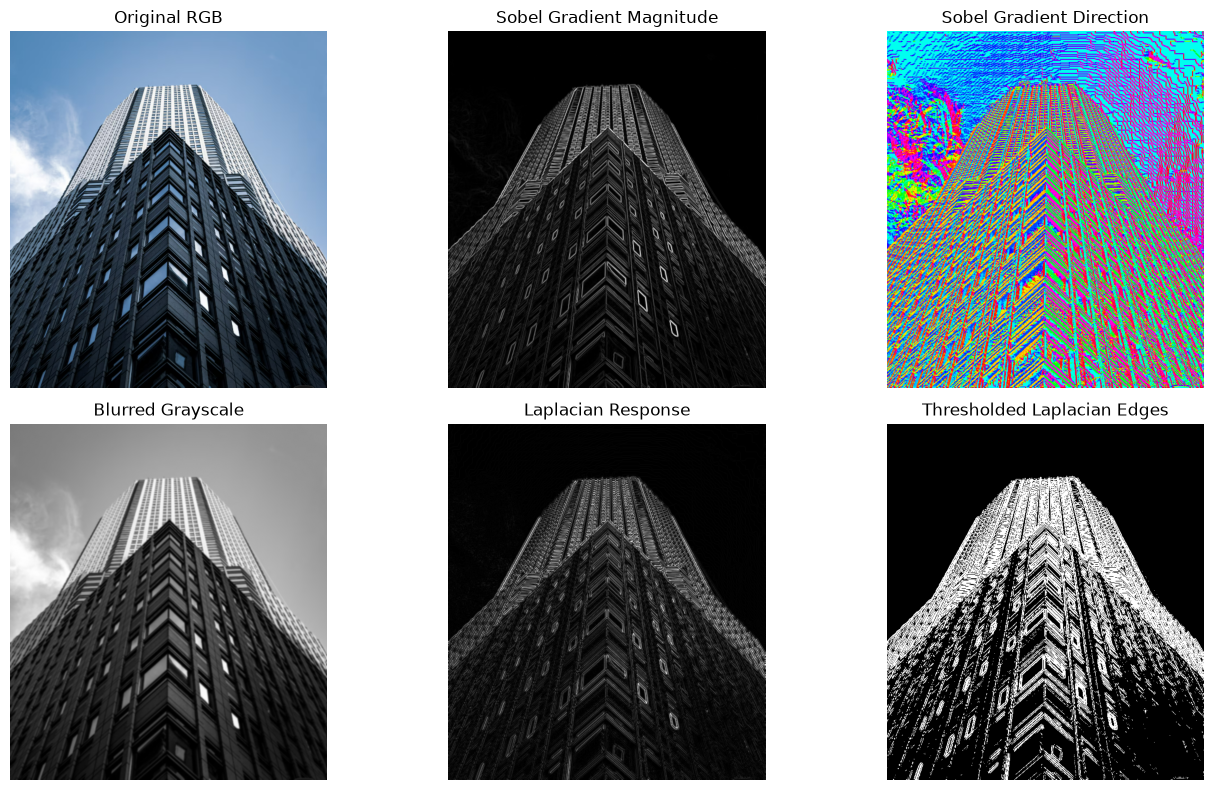

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image
img = cv2.imread("building.png")

if img is None:
    raise FileNotFoundError("Upload building.png")

# Convert to RGB and grayscale
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Sobel gradients
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Gradient magnitude and direction
grad_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
grad_direction = np.arctan2(sobel_y, sobel_x)

# Normalize magnitude
grad_magnitude_norm = cv2.normalize(
    grad_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Normalize direction
grad_direction_norm = (
    (grad_direction + np.pi) / (2 * np.pi) * 255
).astype(np.uint8)

# Blur before Laplacian
blurred = cv2.GaussianBlur(gray, (5, 5), 1)

# Laplacian
laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=3)
laplacian_abs = cv2.convertScaleAbs(laplacian)

# Threshold Laplacian
_, laplacian_thresh = cv2.threshold(
    laplacian_abs, 30, 255, cv2.THRESH_BINARY
)

# Display results
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.imshow(img_rgb)
plt.title("Original RGB")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(grad_magnitude_norm, cmap="gray")
plt.title("Sobel Gradient Magnitude")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(grad_direction_norm, cmap="hsv")
plt.title("Sobel Gradient Direction")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred Grayscale")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(laplacian_abs, cmap="gray")
plt.title("Laplacian Response")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(laplacian_thresh, cmap="gray")
plt.title("Thresholded Laplacian Edges")
plt.axis("off")

plt.tight_layout()
plt.show()

Original pixels: 417850
RLE pairs: 227646
Reconstruction correct: True


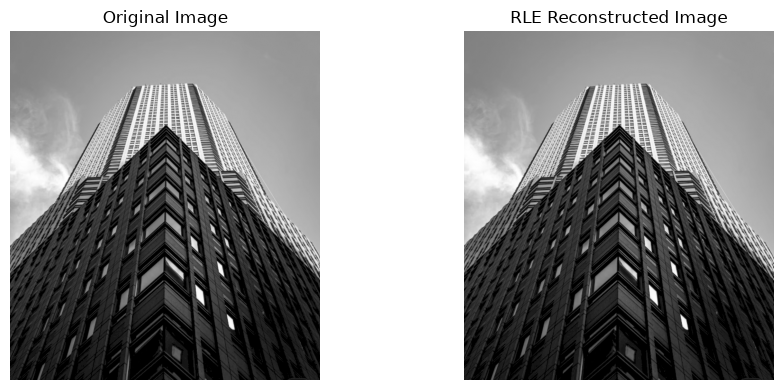

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image in grayscale
img = cv2.imread("building.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Upload building.png")

# Flatten image into 1D array
pixels = img.flatten()

# Run-Length Encoding
rle = []
count = 1

for i in range(1, len(pixels)):
    if pixels[i] == pixels[i - 1]:
        count += 1
    else:
        rle.append((pixels[i - 1], count))
        count = 1

rle.append((pixels[-1], count))

# Decode RLE
decoded = []
for value, count in rle:
    decoded.extend([value] * count)

reconstructed = np.array(decoded, dtype=np.uint8).reshape(img.shape)

# Results
print("Original pixels:", len(pixels))
print("RLE pairs:", len(rle))
print("Reconstruction correct:", np.array_equal(img, reconstructed))

# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed, cmap="gray")
plt.title("RLE Reconstructed Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Number of unique pixel values: 200
Huffman codes: {np.uint8(28): '0000', np.uint8(164): '000100', np.uint8(160): '000101', np.uint8(128): '000110000', np.uint8(4): '000110001000', np.uint8(255): '000110001001', np.uint8(8): '000110001010000', np.uint8(10): '0001100010100010', np.uint8(11): '00011000101000110', np.uint8(13): '000110001010001110', np.uint8(16): '000110001010001111', np.uint8(7): '000110001010010', np.uint8(27): '00011000101001100', np.uint8(29): '000110001010011010', np.uint8(32): '000110001010011011', np.uint8(9): '0001100010100111', np.uint8(6): '00011000101010', np.uint8(5): '00011000101011', np.uint8(3): '000110001011', np.uint8(216): '0001100011', np.uint8(238): '000110010', np.uint8(239): '000110011', np.uint8(144): '0001101', np.uint8(64): '000111', np.uint8(209): '001000000', np.uint8(116): '001000001', np.uint8(142): '00100001', np.uint8(72): '0010001', np.uint8(150): '001001', np.uint8(102): '001010000', np.uint8(250): '001010001', np.uint8(217): '001010010', n

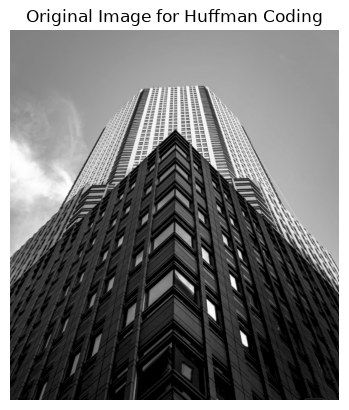

In [5]:
import cv2
import heapq
from collections import Counter
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("building.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Upload building.png")

# Count pixel frequencies
pixels = img.flatten()
frequency = Counter(pixels)

# Build Huffman tree
heap = [[freq, [value, ""]] for value, freq in frequency.items()]
heapq.heapify(heap)

while len(heap) > 1:
    left = heapq.heappop(heap)
    right = heapq.heappop(heap)

    for item in left[1:]:
        item[1] = "0" + item[1]

    for item in right[1:]:
        item[1] = "1" + item[1]

    heapq.heappush(heap, [left[0] + right[0]] + left[1:] + right[1:])

# Generate Huffman codes
huffman_codes = {}
for item in heap[0][1:]:
    huffman_codes[item[0]] = item[1] if item[1] else "0"

# Encode image
encoded = "".join(huffman_codes[pixel] for pixel in pixels)

print("Number of unique pixel values:", len(frequency))
print("Huffman codes:", huffman_codes)
print("Original size (bits):", len(pixels) * 8)
print("Encoded size (bits):", len(encoded))

# Display image
plt.imshow(img, cmap="gray")
plt.title("Original Image for Huffman Coding")
plt.axis("off")
plt.show()

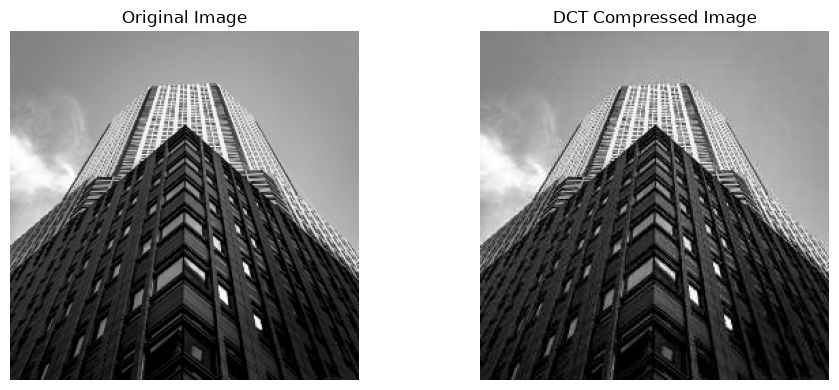

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("building.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Upload building.png")

# Resize image to dimensions divisible by 8
img = cv2.resize(img, (256, 256))

# JPEG quantization table
quant_table = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float32)

# DCT and quantization
compressed = np.zeros_like(img, dtype=np.float32)

for i in range(0, 256, 8):
    for j in range(0, 256, 8):
        block = img[i:i+8, j:j+8].astype(np.float32) - 128
        dct_block = cv2.dct(block)
        quantized = np.round(dct_block / quant_table)
        restored = quantized * quant_table
        idct_block = cv2.idct(restored) + 128
        compressed[i:i+8, j:j+8] = idct_block

# Convert to display format
compressed = np.clip(compressed, 0, 255).astype(np.uint8)

# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(compressed, cmap="gray")
plt.title("DCT Compressed Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Mean intensity: 97.55275816680627
Standard deviation: 73.43290708284549
Minimum intensity: 0
Maximum intensity: 255


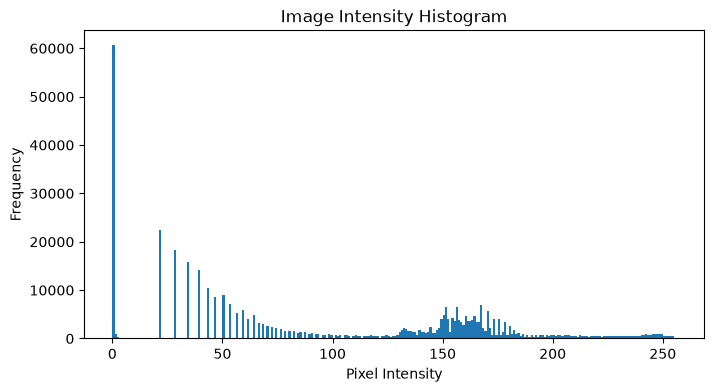

Otsu Threshold Value: 101.0


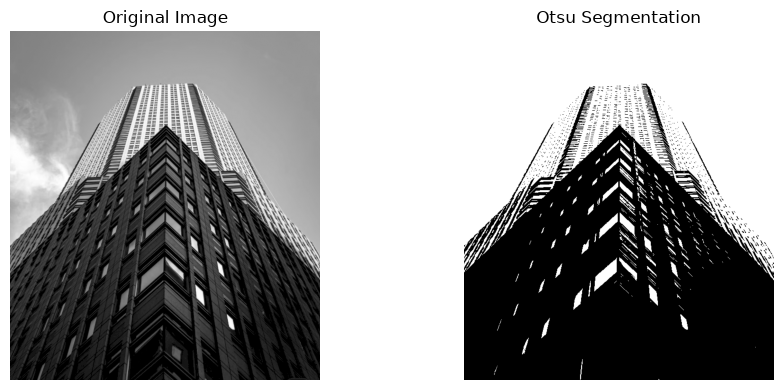

In [6]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("building.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Upload building.png")

# Calculate image statistics
print("Mean intensity:", img.mean())
print("Standard deviation:", img.std())
print("Minimum intensity:", img.min())
print("Maximum intensity:", img.max())

# Create histogram
plt.figure(figsize=(8, 4))
plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.title("Image Intensity Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

# Otsu thresholding
threshold_value, segmented = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold Value:", threshold_value)

# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap="gray")
plt.title("Otsu Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

Contrast: 669.6582437275985
Energy: 0.010385320601293047
Homogeneity: 0.09587559468645002


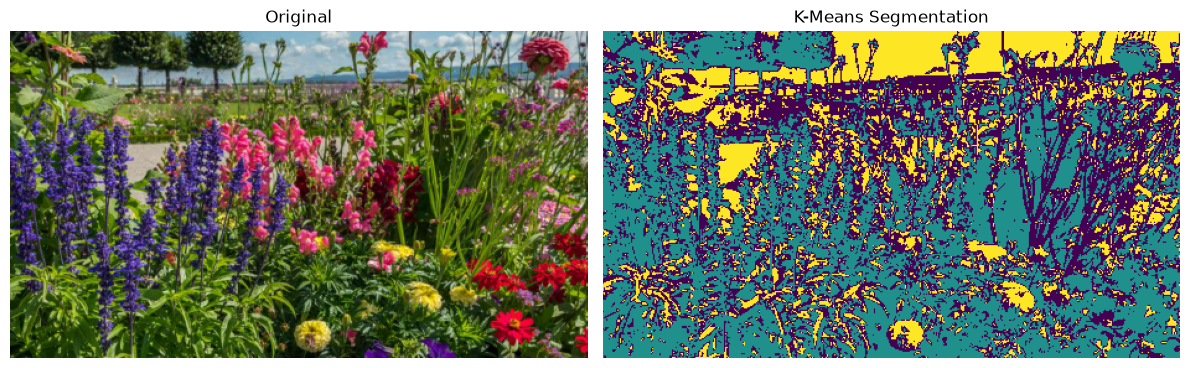

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops

# 1. Load and convert to grayscale
img = cv2.imread("plant.png")

if img is None:
    raise FileNotFoundError("Upload plant.png")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Compute GLCM matrix
glcm = graycomatrix(
    gray,
    distances=[1],
    angles=[0],
    symmetric=True,
    normed=True
)

# 3. Extract texture features
contrast = graycoprops(glcm, 'contrast')[0, 0]
energy = graycoprops(glcm, 'energy')[0, 0]
homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]

print("Contrast:", contrast)
print("Energy:", energy)
print("Homogeneity:", homogeneity)

# 4. K-means segmentation
pixels = gray.reshape((-1, 1)).astype(np.float32)

criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    20, 1.0
)

k = 3

_, labels, centers = cv2.kmeans(
    pixels, k, None, criteria,
    attempts=10,
    flags=cv2.KMEANS_PP_CENTERS
)

segmented = labels.reshape(gray.shape)

# 5. Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img[:, :, ::-1])
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap="viridis")
plt.title("K-Means Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

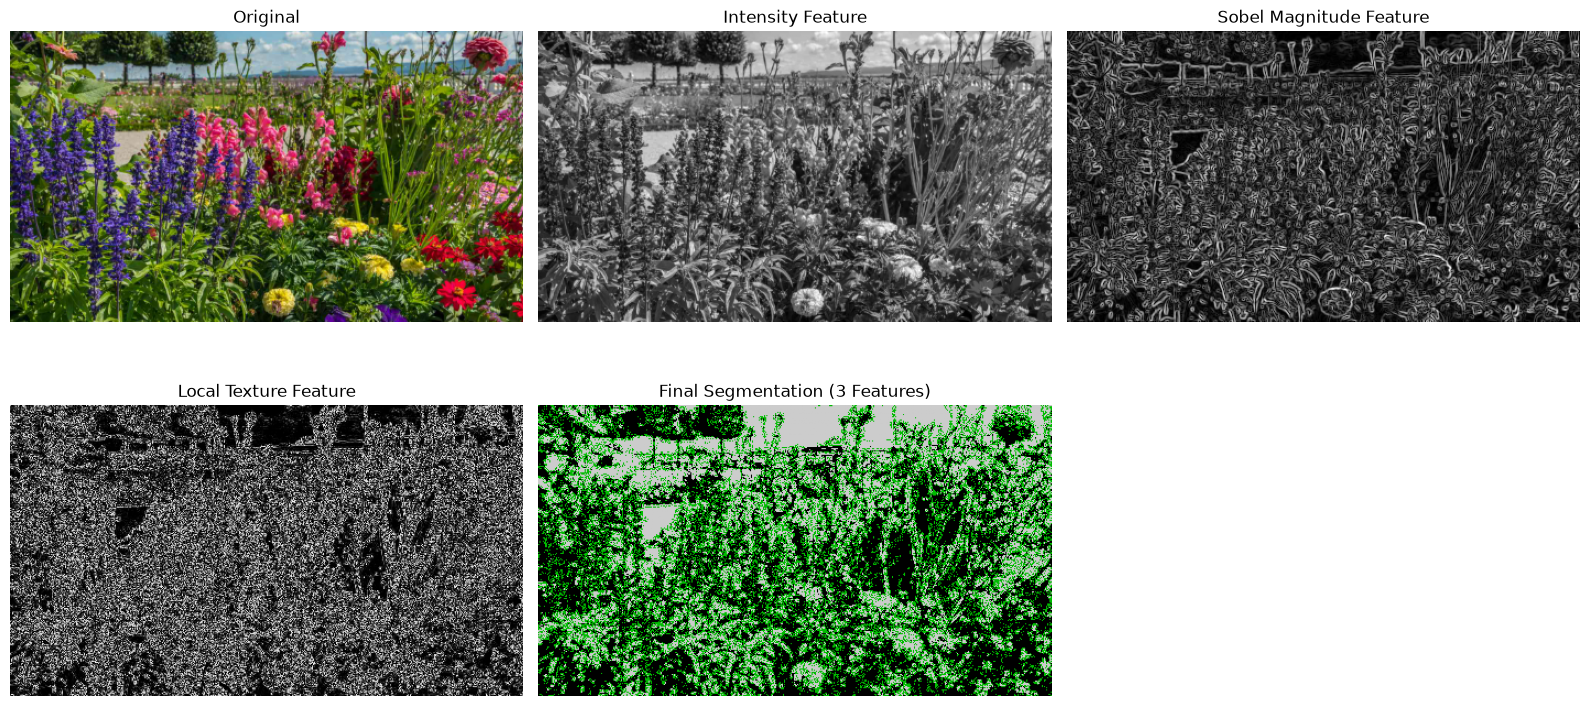

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load image
img = cv2.imread("plant.png")

if img is None:
    raise FileNotFoundError("Upload plant.png")

rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Sobel magnitude
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel_mag = np.sqrt(sobel_x**2 + sobel_y**2)

sobel_mag = cv2.normalize(
    sobel_mag, None, 0, 255, cv2.NORM_MINMAX
)

# 3. Local variance
kernel = np.ones((3, 3), np.float32) / 9.0

blur = cv2.filter2D(gray, -1, kernel)

local_var = (gray - blur)**2

local_var = cv2.normalize(
    local_var, None, 0, 255, cv2.NORM_MINMAX
)

# 4. Prepare feature vector
feature_vector = np.stack([
    gray,
    sobel_mag.astype(np.uint8),
    local_var.astype(np.uint8)
], axis=2)

h, w = gray.shape

fv_flat = feature_vector.reshape(
    (-1, 3)
).astype(np.float32)

# 5. K-means clustering
criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    30, 1.0
)

k = 3

_, labels, centers = cv2.kmeans(
    fv_flat,
    k,
    None,
    criteria,
    attempts=10,
    flags=cv2.KMEANS_PP_CENTERS
)

segmented = labels.reshape((h, w))

# 6. Display results
plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Intensity Feature")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(sobel_mag, cmap="gray")
plt.title("Sobel Magnitude Feature")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(local_var, cmap="gray")
plt.title("Local Texture Feature")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(segmented, cmap="nipy_spectral")
plt.title("Final Segmentation (3 Features)")
plt.axis("off")

plt.tight_layout()
plt.show()